---
title: Lab 6 - Baseball Players
author: Ulises Caro
format: 
    html:
        code-fold: true
        embed-resources: true
echo: true
---

In [3]:
import pandas as pd
import numpy as np
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.linear_model import *
from sklearn.model_selection import *
from sklearn.metrics import *
from sklearn.compose import *
import warnings
from sklearn.exceptions import ConvergenceWarning
from plotnine import *


In [4]:
players_df = pd.read_csv("C:/Users/Ulises Caro Flores/OneDrive/Documents/MSBA Cal Poly/GSB 544 Computing and Machine Learning for Analysis/Week 7/Lab 6/Hitters.csv")
print(players_df.describe())
print(players_df.isna())
print(players_df.info())
print(players_df.isnull().sum())

            AtBat        Hits       HmRun        Runs         RBI       Walks  \
count  322.000000  322.000000  322.000000  322.000000  322.000000  322.000000   
mean   380.928571  101.024845   10.770186   50.909938   48.027950   38.742236   
std    153.404981   46.454741    8.709037   26.024095   26.166895   21.639327   
min     16.000000    1.000000    0.000000    0.000000    0.000000    0.000000   
25%    255.250000   64.000000    4.000000   30.250000   28.000000   22.000000   
50%    379.500000   96.000000    8.000000   48.000000   44.000000   35.000000   
75%    512.000000  137.000000   16.000000   69.000000   64.750000   53.000000   
max    687.000000  238.000000   40.000000  130.000000  121.000000  105.000000   

            Years       CAtBat        CHits      CHmRun        CRuns  \
count  322.000000    322.00000   322.000000  322.000000   322.000000   
mean     7.444099   2648.68323   717.571429   69.490683   358.795031   
std      4.926087   2324.20587   654.472627   86.26606

In [4]:
#this will helps us get rid of the rows that have an empty value under Salary since it's the only column with empty values

players_df = players_df.dropna(subset="Salary")
players_df = players_df.reset_index(drop=True)
print(len(players_df))

263


In [5]:
X = players_df.drop(columns=["Salary"])
y = players_df["Salary"]

X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.20,random_state=321)

In [6]:
ct = ColumnTransformer(
    [("scalar", StandardScaler(), make_column_selector(dtype_include=np.number)),
     ("ohe", OneHotEncoder(drop="first", handle_unknown='ignore', sparse_output = False), make_column_selector(dtype_include=object))],
    remainder="passthrough"
)


**Part 1: Different Model Specs**

A. Regression without regularization

In [7]:
pipeline_linear = Pipeline(
    [('preprocessing', ct),
     ('lr', LinearRegression())]
)

pipeline_linear.fit(X_train, y_train)

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('scalar', StandardScaler(),
                                                  <sklearn.compose._column_transformer.make_column_selector object at 0x7843f2ce3d40>),
                                                 ('ohe',
                                                  OneHotEncoder(drop='first',
                                                                handle_unknown='ignore',
                                                                sparse_output=False),
                                                  <sklearn.compose._column_transformer.make_column_selector object at 0x7843f2ce3920>)])),
                ('lr', LinearRegression())])

In [8]:
#Getting the coefficients of the linear regression

lr_coefs = pipeline_linear.named_steps['lr'].coef_
lr_coef_names = pipeline_linear.named_steps["preprocessing"].get_feature_names_out()
lr_coef_df = pd.DataFrame({"Variable": lr_coef_names, "Coef": lr_coefs})

lr_coef_df.sort_values(by='Coef', key=lambda s: np.abs(s), ascending=False)

,Variable,Coef
10,scalar__CRuns,387.709577
1,scalar__Hits,317.084546
7,scalar__CAtBat,-294.306233
11,scalar__CRBI,213.563514
12,scalar__CWalks,-212.071954
0,scalar__AtBat,-204.583001
5,scalar__Walks,146.424893
8,scalar__CHits,103.821339
17,ohe__Division_W,-94.977463
16,ohe__League_N,88.170541


We want to look at the absolute value of the ceofficients and interpret them based on the magnitude. More so, when interpretting the coefficients, we must be note that the inference comes given all else constant so we only capture the effect of that PV for the regression. I've chosen the first highest in magnitude for numeric and the highest for the a categorical variable.


*   CRuns: All else constant, for each standard deviation increase in career runs, the predicted 1987 salary, on average, increases by $387.71 (in thousands) on opening day.

*   Hits: All else constant, for each standard deviation increase in hits during 1986, the predicted 1987 salary, on average, increases by $317.08 (in thousands) on opening day.

*   CAtBAt: All else constant, for each standard deviation increase in times at bat during their career, the predicted 1987 salary, on average, decreases by $294.31 (in thousands) on opening day.

*   CRBI: All else constant, for each standard deviation increase in runs batted during career, the predicted 1987 salary, on average, increases $213.56 (in thousands) on opening day.

*   CWalks:All else constant, for each standard deviation increase in career walks, the predicted 1987 salary, on average, decreases by $212.07 (in thousands) on opening day.

*   Division: All else constant, the predicted 1987 salary, on average, is $94.98 (in thousands) less on opening day for those with careers in the west compared to the east.







In [9]:
#predicted MSE for the Salary given the year 1989

cv_scores = cross_val_score(pipeline_linear, X_train, y_train, scoring='neg_mean_squared_error', cv=5)
estimated_mse = -cv_scores.mean()

print(f"Estimated MSE for 1989 Salary under OLS: {estimated_mse:.4f}")

Estimated MSE for 1989 Salary under OLS: 117385.0795


In [10]:
#This is getting the MSE, RMSE, MAE, and R-squared for the model
#We will follow this same protocol to the same for the Lasso and Ridge

y_pred1 = pipeline_linear.predict(X_test)
linear_mse = mean_squared_error(y_test, y_pred1)
linear_r2 = r2_score(y_test, y_pred1)
linear_mae = mean_absolute_error(y_test, y_pred1)
linear_rmse = root_mean_squared_error(y_test, y_pred1)
print(f"Linear Regression MSE: {linear_mse: .4f}")
print(f'Linear Regression R2: {linear_r2: .4f}')
print(f'Linear Regression MAE: {linear_mae: .4f}')
print(f'Linear Regression RMSE: {linear_rmse: .4f}')

Linear Regression MSE:  146087.4506
Linear Regression R2:  0.2262
Linear Regression MAE:  236.3914
Linear Regression RMSE:  382.2139


B. Ridge Regression

In [11]:
alphas = np.logspace(-3, 3, 25)

ridge_regression = Pipeline([
    ("preprocessing", ct),
    ("ridge", RidgeCV(alphas=alphas, cv=5,
                      scoring="neg_mean_squared_error"))
])

ridge_regression.fit(X_train, y_train)

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('scalar', StandardScaler(),
                                                  <sklearn.compose._column_transformer.make_column_selector object at 0x7843f2ce3d40>),
                                                 ('ohe',
                                                  OneHotEncoder(drop='first',
                                                                handle_unknown='ignore',
                                                                sparse_output=False),
                                                  <sklearn.compose._column_transformer.make_column_selector object at 0x7843f2...
       1.00000000e-02, 1.77827941e-02, 3.16227766e-02, 5.62341325e-02,
       1.00000000e-01, 1.77827941e-01, 3.16227766e-01, 5.62341325e-01,
       1.00000000e+00, 1.77827941e+00, 3.16227766e+00, 5.62341325e+00,
       1.00000000e+01, 1.77827941e+01, 3.16227766e+01, 5.62341325e+01,
       1.00000000e+02, 1.77827941e+02, 3.16227766e+02, 5.62341325e+02,
       1.00000000e+03]),
                         cv=5, scoring='neg_mean_squared_error'))])

In [12]:
best_alpha = ridge_regression.named_steps["ridge"].alpha_
print("Best alpha:", best_alpha)

Best alpha: 31.622776601683793


In [13]:
#fitting the model with the best alpha.

final_ridge = Pipeline(
    [("preprocessing", ct),
     ("final_ridge", Ridge(alpha=best_alpha))]).fit(X, y)

#Getting the coefficients of the Ridge regression


ridge_coefs = final_ridge.named_steps['final_ridge'].coef_
ridge_coef_names = final_ridge.named_steps["preprocessing"].get_feature_names_out()
ridge_coef_df = pd.DataFrame({"Variable": ridge_coef_names, "Coef": ridge_coefs})

ridge_coef_df.sort_values(by='Coef', key=lambda s: np.abs(s), ascending=False)

,Variable,Coef
17,ohe__Division_W,-88.443271
1,scalar__Hits,84.825154
10,scalar__CRuns,70.131642
13,scalar__PutOuts,69.645654
11,scalar__CRBI,67.830958
8,scalar__CHits,65.930128
5,scalar__Walks,57.069146
9,scalar__CHmRun,50.110223
0,scalar__AtBat,-49.349124
12,scalar__CWalks,-33.568049


Considering the regression has been penalized by applying a ridge regularization, we still interpret these coefficients in respect to standard deviations and all else constant to only focus on the influence of the PV.

*   Division: All else constant, the predicted 1987 salary, on average, is $88.4 (in thousand) less on opening day for those with careers in the west compared to the east.

*   Hits: All else constant, for each standard deviation increase in hits during 1986, the predicted 1987 salary, on average, increases by $84.82 (in thousands) on opening day.

*   CRuns: All else constant, for each standard deviation increase in career runs, the predicted 1987 salary, on average, increases by $70.13 (in thousands) on opening day.

*   PutOuts: All else constant, for each standard deviation increase in put outs during 1986, the predicted 1987 salary, on average, increases by $69.65 (in thousands) on opening day.


*   CRBI: All else constant, for each standard deviation increase in runs batted during career, the predicted 1987 salary, on average, increases by $67.83 (in thousands) on opening day

*   CHits: All else constant, for each standard deviation increase in career hits, the predicted 1987 salary, on average, increases by $65.93 (in thousands) on opening day



In [23]:
#predicted MSE for the Salary given the year 1989

cv_scores2 = cross_val_score(final_ridge, X_train, y_train, scoring='neg_mean_squared_error', cv=5)
estimated_mse2 = -cv_scores2.mean()

print(f"Estimated MSE for 1989 Salary under a Ridge Regression: {estimated_mse2:.4f}")

Estimated MSE for 1989 Salary under a Ridge Regression: 108161.2292


In [24]:
y_pred2 = final_ridge.predict(X_test)
ridge_mse = mean_squared_error(y_test, y_pred2)
ridge_r2 = r2_score(y_test, y_pred2)
ridge_mae = mean_absolute_error(y_test, y_pred2)
ridge_rmse = root_mean_squared_error(y_test, y_pred2)
print(f"Ridge Regression MSE: {ridge_mse: .4f}")
print(f"Ridge Regression R2: {ridge_r2: .4f}")
print(f"Ridge Regression MAE: {ridge_mae: .4f}")
print(f"Ridge Regression RMSE: {ridge_rmse: .4f}")

Ridge Regression MSE:  134193.1013
Ridge Regression R2:  0.2892
Ridge Regression MAE:  218.8111
Ridge Regression RMSE:  366.3238


3. Lasso Regression

In [25]:
lambdas = np.logspace(-3, 1, 25)

lasso_regression = Pipeline([
    ("preprocessing", ct),
    ("lasso", LassoCV(alphas=lambdas, cv=5, max_iter=10000))
])

lasso_regression.fit(X_train, y_train)

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('scalar', StandardScaler(),
                                                  <sklearn.compose._column_transformer.make_column_selector object at 0x7843f2ce3d40>),
                                                 ('ohe',
                                                  OneHotEncoder(drop='first',
                                                                handle_unknown='ignore',
                                                                sparse_output=False),
                                                  <sklearn.compose._column_transformer.make_column_selector object at 0x7843f2...
                 LassoCV(alphas=array([1.00000000e-03, 1.46779927e-03, 2.15443469e-03, 3.16227766e-03,
       4.64158883e-03, 6.81292069e-03, 1.00000000e-02, 1.46779927e-02,
       2.15443469e-02, 3.16227766e-02, 4.64158883e-02, 6.81292069e-02,
       1.00000000e-01, 1.46779927e-01, 2.15443469e-01, 3.16227766e-01,
       4.64158883e-01, 6.81292069e-01, 1.00000000e+00, 1.46779927e+00,
       2.15443469e+00, 3.16227766e+00, 4.64158883e+00, 6.81292069e+00,
       1.00000000e+01]),
                         cv=5, max_iter=10000))])

In [26]:
best_alpha_lasso = lasso_regression.named_steps["lasso"].alpha_
print("Best alpha for Lasso:", best_alpha_lasso)

Best alpha for Lasso: 10.0


In [27]:
#fitting the model with the best alpha (lambda).

final_lasso = Pipeline(
    [("preprocessing", ct),
     ("final_ridge", Lasso(alpha=best_alpha_lasso))]).fit(X, y)

#Getting the coefficients of the Lasso regression


lasso_coefs = final_lasso.named_steps['final_ridge'].coef_
lasso_coef_names = final_lasso.named_steps["preprocessing"].get_feature_names_out()
lasso_coef_df = pd.DataFrame({"Variable": lasso_coef_names, "Coef": lasso_coefs})

lasso_coef_df.sort_values(by='Coef', key=lambda s: np.abs(s), ascending=False)

,Variable,Coef
11,scalar__CRBI,134.031514
17,ohe__Division_W,-95.413752
1,scalar__Hits,88.741616
10,scalar__CRuns,72.228080
13,scalar__PutOuts,66.737033
5,scalar__Walks,49.902786
15,scalar__Errors,-4.158285
2,scalar__HmRun,0.000000
0,scalar__AtBat,-0.000000
4,scalar__RBI,0.000000


After applying the lasso regularization, we can see further shrinkage with some variables. Similarly, we'll comment on the first 5 numeric variables followed by then


*   CRBI: All else constant, for each standard deviation increase runs batted during career, the predicted 1987 salary, on average, increases by $134.03 (in thousands) on opening day.

*   Division: All else constant, the predicted 1987 salary, on average, is $95.41 (in thousands) less on opening day for those with careers in the west compared to the east.

*   Hits: All else constant, for each standard deviation increase in hits during 1986, the predicted 1987 salary, on average, decreases by $135.47 (in thousands) on opening day

*   CRuns: All else constant, for each standard deviation increase in career runs, the predicted 1987 salary, on average, increases by $72.23 (in thousands) on opening day.

*   PutOuts: All else constant, for each standard deviation increase in career hits, the predicted 1987 salary, on average, increases by $66.73 (in thousands) on opening day.


*   Walks: All else constant, for each standard deviation increase in walks during 1986, the predicted 1987 salary, on average, increases by $49.90 (in thousands) on opening day.





In [28]:
#predicted MSE for the Salary given the year 1989

cv_scores3 = cross_val_score(final_lasso, X_train, y_train, scoring='neg_mean_squared_error', cv=5)
estimated_mse3 = -cv_scores3.mean()

print(f"Estimated MSE for 1989 Salary under Lasso Regression: {estimated_mse3:.4f}")

Estimated MSE for 1989 Salary under Lasso Regression: 109799.8673


In [29]:
y_pred3 = final_lasso.predict(X_test)
lasso_mse = mean_squared_error(y_test, y_pred3)
lasso_r2 = r2_score(y_test, y_pred3)
lasso_mae = mean_absolute_error(y_test, y_pred3)
lasso_rmse = root_mean_squared_error(y_test, y_pred3)
print(f"Lasso Regression MSE: {lasso_mse: .4f}")
print(f"Lasso Regression R2: {lasso_r2: .4f}")
print(f"Lasso Regression MAE: {lasso_mae: .4f}")
print(f"Lasso Regression RMSE: {lasso_rmse: .4f}")

Lasso Regression MSE:  140116.2571
Lasso Regression R2:  0.2578
Lasso Regression MAE:  225.2554
Lasso Regression RMSE:  374.3211


D. Elastic Net

In [30]:
enet_param = {
    "alphas": np.logspace(-3, 1, 25),
    "l1_ratio": np.linspace(0.1, 0.9, 10)
}

enet_regression = Pipeline([
    ("preprocessing", ct),
    ("enet", ElasticNetCV(alphas=enet_param["alphas"], l1_ratio=enet_param["l1_ratio"], cv=5, max_iter=10000))
])

enet_regression.fit(X_train, y_train)

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('scalar', StandardScaler(),
                                                  <sklearn.compose._column_transformer.make_column_selector object at 0x7843f2ce3d40>),
                                                 ('ohe',
                                                  OneHotEncoder(drop='first',
                                                                handle_unknown='ignore',
                                                                sparse_output=False),
                                                  <sklearn.compose._column_transformer.make_column_selector object at 0x7843f2...
       2.15443469e-02, 3.16227766e-02, 4.64158883e-02, 6.81292069e-02,
       1.00000000e-01, 1.46779927e-01, 2.15443469e-01, 3.16227766e-01,
       4.64158883e-01, 6.81292069e-01, 1.00000000e+00, 1.46779927e+00,
       2.15443469e+00, 3.16227766e+00, 4.64158883e+00, 6.81292069e+00,
       1.00000000e+01]),
                              cv=5,
                              l1_ratio=array([0.1       , 0.18888889, 0.27777778, 0.36666667, 0.45555556,
       0.54444444, 0.63333333, 0.72222222, 0.81111111, 0.9       ]),
                              max_iter=10000))])

In [31]:
best_alpha_enet = enet_regression.named_steps["enet"].alpha_
best_l1_ratio_enet = enet_regression.named_steps["enet"].l1_ratio_

print("Best alpha for Elastic Net:", best_alpha_enet)
print("Best l1_ratio for Elastic Net:", best_l1_ratio_enet)

Best alpha for Elastic Net: 0.46415888336127775
Best l1_ratio for Elastic Net: 0.6333333333333333


In [32]:
#fitting the model with the best parameters.

final_enet = Pipeline(
    [("preprocessing", ct),
     ("final_enet", ElasticNet(alpha=best_alpha_enet))]).fit(X, y)

#Getting the coefficients of the Elastic Net regularization


enet_coefs = final_enet.named_steps['final_enet'].coef_
enet_coef_names = final_enet.named_steps["preprocessing"].get_feature_names_out()
enet_coef_df = pd.DataFrame({"Variable": enet_coef_names, "Coef": enet_coefs})

enet_coef_df.sort_values(by='Coef', key=lambda s: np.abs(s), ascending=False)

,Variable,Coef
17,ohe__Division_W,-68.232650
13,scalar__PutOuts,63.315462
1,scalar__Hits,61.243411
11,scalar__CRBI,54.630752
10,scalar__CRuns,53.635952
8,scalar__CHits,51.781006
5,scalar__Walks,46.834666
9,scalar__CHmRun,42.967106
3,scalar__Runs,30.475359
4,scalar__RBI,22.978876



*   Division: All else constant, the predicted 1987 salary, on average, is $68.23 (in thousands) less on opening day for those with careers in the west compared to the east.

*   PutOuts: All else constant, for each standard deviation increase in put outs during 1986, the predicted 1987 salary, on average, increases by $63.31 (in thousands) on opening day.

*   Hits: All else constant, for each standard deviation increase in hits during 1986, the predicted 1987 salary, on average, increases by $61.24 (in thousands) on opening day.

*   CRBI: All else constant, for each standard deviation increase in runs batted during career, the predicted 1987 salary, on average, decreases by $54.63 (in thousands) on opening day

*   CRuns: All else constant, for each standard deviation increase in career runs, the predicted 1987 salary, on average, increases by $53.63 (in thousands) on opening day.


*   CHits: All else constant, for each standard deviation increase in career hits, the predicted 1987 salary, on average, increases by $51.78 (in thousands) on opening day.


In [33]:
#predicted MSE for the Salary given the year 1989

cv_scores4 = cross_val_score(final_enet, X_train, y_train, scoring='neg_mean_squared_error', cv=5)
estimated_mse4 = -cv_scores4.mean()

print(f"Estimated MSE for 1989 Salary under Elastic Net Regression: {estimated_mse4:.4f}")

Estimated MSE for 1989 Salary under Elastic Net Regression: 108196.6916


In [34]:
y_pred4 = final_enet.predict(X_test)
enet_mse = mean_squared_error(y_test, y_pred4)
enet_r2 = r2_score(y_test, y_pred4)
enet_mae = mean_absolute_error(y_test, y_pred4)
enet_rmse = root_mean_squared_error(y_test, y_pred4)
print(f"Elastic Net MSE: {enet_mse: .4f}")
print(f"Elastic Net R2: {enet_r2: .4f}")
print(f"Elastic Net MAE: {enet_mae: .4f}")
print(f"Elastic Net RMSE: {enet_rmse: .4f}")

Elastic Net MSE:  137099.5606
Elastic Net R2:  0.2738
Elastic Net MAE:  218.9850
Elastic Net RMSE:  370.2696


In [35]:
table = pd.DataFrame(data = {"Linear Regression": [linear_mse, linear_r2, linear_mae, linear_rmse], "Ridge Regression": [ridge_mse, ridge_r2, ridge_mae, ridge_rmse],  "Lasso Regression": [lasso_mse, lasso_r2, lasso_mae, lasso_rmse], "Elastic Net": [enet_mse, enet_r2, enet_mae, enet_rmse]}, index=['MSE',"R^2","MAE","RMSE"])
table.style.format({'Linear Regression': '{:,.4f}', 'Ridge Regression': '{:,.4f}', 'Lasso Regression': '{:,.4f}', 'Elastic Net': '{:,.4f}'})

,Linear Regression,Ridge Regression,Lasso Regression,Elastic Net
MSE,"146,087.4506","134,193.1013","140,116.2571","137,099.5606"
R^2,0.2262,0.2892,0.2578,0.2738
MAE,236.3914,218.8111,225.2554,218.9850
RMSE,382.2139,366.3238,374.3211,370.2696


In [36]:
estimate_all = pd.DataFrame(data = {"Linear MSE 1989": [estimated_mse], "Ridge MSE 1989": [estimated_mse2], "Lasso MSE 1989": [estimated_mse3], "Elastic Net MSE": [estimated_mse4]}, index=["MSE"])
estimate_all.style.format({'Linear MSE 1989': '{:,.4f}', 'Ridge MSE 1989': '{:,.4f}', 'Lasso MSE 1989': '{:,.4f}', 'Elastic Net MSE 1989': '{:,.4f}'})

,Linear MSE 1989,Ridge MSE 1989,Lasso MSE 1989,Elastic Net MSE
MSE,"117,385.0795","108,161.2292","109,799.8673",108196.691609


**Based on the table, it is likely that Ridge was the best model such that after imposing a penalty and simplifying the model, we see that it has the lowest MSE and highest R2 of the 4 models**

**More so, in each model, the categorical variable that stood out each time and likely the most import was "Division."**

**In terms of the numeric variables, we saw that Hits, CRuns, and CRBI showed up in each model. However, some of these varied abit, but we see that PutOut and Walks were in the top.**

**Out of these variables, Hits seems to be the most important.**

**Part 2**

**Only the top numeric Variable**

In [37]:
X_hits = X[['Hits']]

X_train_hits, X_test_hits, y_train_hits, y_test_hits = train_test_split(X_hits, y, test_size=0.20, random_state=321)

In [38]:
pipeline_linear.fit(X_hits, y)
cv_linear1 = cross_val_score(pipeline_linear, X_train[['Hits']], y_train,
                             scoring='neg_mean_squared_error', cv=5)
estmse_linear1 = -cv_linear1.mean()
print(f"Estimated MSE for top numeric variable: {estmse_linear1:.4f}")

Estimated MSE for top numeric variable: 157464.5655


In [39]:
y_plr1 = pipeline_linear.predict(X_test_hits)
linear_mse2 = mean_squared_error(y_test_hits, y_plr1)
linear_r2_2 = r2_score(y_test_hits, y_plr1)
linear_mae2 = mean_absolute_error(y_test_hits, y_plr1)
linear_rmse2 = root_mean_squared_error(y_test_hits, y_plr1)
print(f"Linear Regression MSE: {linear_mse2: .4f}")
print(f'Linear Regression R2: {linear_r2_2: .4f}')
print(f'Linear Regression MAE: {linear_mae2: .4f}')
print(f'Linear Regression RMSE: {linear_rmse2: .4f}')

Linear Regression MSE:  212100.8149
Linear Regression R2: -0.1235
Linear Regression MAE:  325.7667
Linear Regression RMSE:  460.5440


In [40]:
alphas = np.logspace(-3, 3, 25)

ridge_regression = Pipeline([
    ("preprocessing", ct),
    ("ridge", RidgeCV(alphas=alphas, cv=5,
                      scoring="neg_mean_squared_error"))
])

ridge_regression.fit(X_train_hits, y_train_hits)
best_alpha = ridge_regression.named_steps["ridge"].alpha_
print("Best alpha:", best_alpha)

Best alpha: 0.001


In [75]:
final_ridge = Pipeline(
    [("preprocessing", ct),
     ("final_ridge", Ridge(alpha=best_alpha))]).fit(X_hits, y)

cv_ridge1 = cross_val_score(final_ridge, X_train_hits, y_train_hits, scoring='neg_mean_squared_error', cv=5)
estmse_ridge1 = -cv_ridge1.mean()
print(f"Estimated MSE for top numeric variable: {estmse_ridge1:.4f}")

Estimated MSE for top numeric variable: 157464.5646


In [70]:
y_pr1 = final_ridge.predict(X_test_hits)
ridge_mse2 = mean_squared_error(y_test_hits, y_pr1)
ridge_r2_2 = r2_score(y_test_hits, y_pr1)
ridge_mae2 = mean_absolute_error(y_test_hits, y_pr1)
ridge_rmse2 = root_mean_squared_error(y_test_hits, y_pr1)
print(f"Ridge Regression MSE: {ridge_mse2: .4f}")
print(f"Ridge Regression R2: {ridge_r2_2: .4f}")
print(f"Ridge Regression MAE: {ridge_mae2: .4f}")
print(f"Ridge Regression RMSE: {ridge_rmse2: .4f}")

Ridge Regression MSE:  212100.5774
Ridge Regression R2: -0.1235
Ridge Regression MAE:  325.7666
Ridge Regression RMSE:  460.5438


In [71]:
lambdas = np.logspace(-3, 1, 25)

lasso_regression = Pipeline([
    ("preprocessing", ct),
    ("lasso", LassoCV(alphas=lambdas, cv=5, max_iter=50000))
])

lasso_regression.fit(X_train_hits, y_train_hits)

best_alpha_lasso = lasso_regression.named_steps["lasso"].alpha_
print("Best alpha for Lasso:", best_alpha_lasso)


Best alpha for Lasso: 0.001


In [72]:
final_lasso = Pipeline(
    [("preprocessing", ct),
     ("lasso", Lasso(alpha=best_alpha_lasso, max_iter=50000))]).fit(X_hits, y)

cv_lasso1 = cross_val_score(final_lasso, X_train_hits, y_train_hits, scoring='neg_mean_squared_error', cv=5)
estmse_lasso1 = -cv_lasso1.mean()
print(f"Estimated MSE for top numeric variable: {estmse_lasso1:.4f}")

Estimated MSE for top numeric variable: 157464.5792


In [73]:
y_pl1 = final_lasso.predict(X_test_hits)
lasso_mse2 = mean_squared_error(y_test_hits, y_pl1)
lasso_r2_2 = r2_score(y_test_hits, y_pl1)
lasso_mae2 = mean_absolute_error(y_test_hits, y_pl1)
lasso_rmse2 = root_mean_squared_error(y_test_hits, y_pl1)
print(f"Lasso Regression MSE: {lasso_mse2: .4f}")
print(f"Lasso Regression R2: {lasso_r2_2: .4f}")
print(f"Lasso Regression MAE: {lasso_mae2: .4f}")
print(f"Lasso Regression RMSE: {lasso_rmse2: .4f}")

Lasso Regression MSE:  212100.4986
Lasso Regression R2: -0.1235
Lasso Regression MAE:  325.7665
Lasso Regression RMSE:  460.5437


In [66]:
enet_param = {
    "alphas": np.logspace(-3, 1, 100),
    "l1_ratio": np.linspace(0.1, 0.9, 10)
}

enet_regression = Pipeline([
    ("preprocessing", ct),
    ("enet", ElasticNetCV(alphas=enet_param["alphas"], l1_ratio=enet_param["l1_ratio"], cv=5, max_iter=10000))
])

enet_regression.fit(X_train_hits, y_train_hits)

best_alpha_enet = enet_regression.named_steps["enet"].alpha_
best_l1_ratio_enet = enet_regression.named_steps["enet"].l1_ratio_

print("Best alpha for Elastic Net:", best_alpha_enet)
print("Best l1_ratio for Elastic Net:", best_l1_ratio_enet)

Best alpha for Elastic Net: 0.001
Best l1_ratio for Elastic Net: 0.9


In [76]:
warnings.filterwarnings("ignore", category=ConvergenceWarning)

final_enet = Pipeline(
    [("preprocessing", ct),
     ("final_enet", ElasticNet(alpha=best_alpha_enet))]).fit(X_hits, y)

cv_enet1 = cross_val_score(final_enet, X_train, y_train, scoring='neg_mean_squared_error', cv=5)
estmse_enet1 = -cv_enet1.mean()

warnings.filterwarnings("default", category=ConvergenceWarning)

print(f"Estimated MSE for 1989 Salary under Elastic Net Regression: {estmse_enet1:.4f}")

Estimated MSE for 1989 Salary under Elastic Net Regression: 115516.9931


In [77]:
y_penet1 = final_enet.predict(X_test_hits)
enet_mse2 = mean_squared_error(y_test_hits, y_penet1)
enet_r2_2 = r2_score(y_test_hits, y_penet1)
enet_mae2 = mean_absolute_error(y_test_hits, y_penet1)
enet_rmse2 = root_mean_squared_error(y_test_hits, y_penet1)
print(f"Elastic Net MSE: {enet_mse2: .4f}")
print(f"Elastic Net R2: {enet_r2_2: .4f}")
print(f"Elastic Net MAE: {enet_mae2: .4f}")
print(f"Elastic Net RMSE: {enet_rmse2: .4f}")

Elastic Net MSE:  212069.4445
Elastic Net R2: -0.1233
Elastic Net MAE:  325.7456
Elastic Net RMSE:  460.5100


**The 5 top numeric variables**

In [79]:
X_top5 = X[['Hits', 'CRBI', 'CRuns', 'Walks', 'PutOuts']]

X_train_top5, X_test_top5, y_train_top5, y_test_top5 = train_test_split(X_top5, y, test_size=0.20, random_state=321)

In [80]:
pipeline_linear.fit(X_train_top5, y_train_top5)
cv_linear2 = cross_val_score(pipeline_linear, X_train_top5, y_train_top5, scoring='neg_mean_squared_error', cv=5)
estmse_linear2 = -cv_linear2.mean()
print(f"Estimated MSE for top 5 numeric variable: {estmse_linear2:.4f}")

Estimated MSE for top 5 numeric variable: 107563.6313


In [81]:
y_plr2 = pipeline_linear.predict(X_test_top5)
linear_mse3 = mean_squared_error(y_test_top5, y_plr2)
linear_r2_3 = r2_score(y_test_top5, y_plr2)
linear_mae3 = mean_absolute_error(y_test_top5, y_plr2)
linear_rmse3 = root_mean_squared_error(y_test_top5, y_plr2)
print(f"Linear Regression MSE: {linear_mse3: .4f}")
print(f'Linear Regression R2: {linear_r2_3: .4f}')
print(f'Linear Regression MAE: {linear_mae3: .4f}')
print(f'Linear Regression RMSE: {linear_rmse3: .4f}')

Linear Regression MSE:  174883.9716
Linear Regression R2:  0.0737
Linear Regression MAE:  256.0250
Linear Regression RMSE:  418.1913


In [82]:
alphas = np.logspace(-3, 3, 25)

ridge_regression = Pipeline([
    ("preprocessing", ct),
    ("ridge", RidgeCV(alphas=alphas, cv=5,
                      scoring="neg_mean_squared_error"))
])

ridge_regression.fit(X_train_top5, y_train_top5)
best_alpha = ridge_regression.named_steps["ridge"].alpha_
print("Best alpha:", best_alpha)

Best alpha: 31.622776601683793


In [83]:
final_ridge = Pipeline(
    [("preprocessing", ct),
     ("final_ridge", Ridge(alpha=best_alpha))]).fit(X_top5, y)

cv_ridge2 = cross_val_score(final_ridge, X_train_top5, y_train_top5, scoring='neg_mean_squared_error', cv=5)
estmse_ridge2 = -cv_ridge2.mean()
print(f"Estimated MSE for top numeric variable: {estmse_ridge2:.4f}")

Estimated MSE for top numeric variable: 105046.9775


In [84]:
y_pr2 = final_ridge.predict(X_test_top5)
ridge_mse3 = mean_squared_error(y_test_top5, y_pr2)
ridge_r2_3 = r2_score(y_test_hits, y_pr2)
ridge_mae3 = mean_absolute_error(y_test_top5, y_pr2)
ridge_rmse3 = root_mean_squared_error(y_test_top5, y_pr2)
print(f"Ridge Regression MSE: {ridge_mse3: .4f}")
print(f"Ridge Regression R2: {ridge_r2_3: .4f}")
print(f"Ridge Regression MAE: {ridge_mae3: .4f}")
print(f"Ridge Regression RMSE: {ridge_rmse3: .4f}")

Ridge Regression MSE:  149687.9903
Ridge Regression R2:  0.2071
Ridge Regression MAE:  234.0024
Ridge Regression RMSE:  386.8953


In [85]:
lambdas = np.logspace(-3, 1, 25)

lasso_regression = Pipeline([
    ("preprocessing", ct),
    ("lasso", LassoCV(alphas=lambdas, cv=5, max_iter=50000))
])

lasso_regression.fit(X_train_top5, y_train_top5)

best_alpha_lasso = lasso_regression.named_steps["lasso"].alpha_
print("Best alpha for Lasso:", best_alpha_lasso)

Best alpha for Lasso: 4.6415888336127775


In [86]:
final_lasso = Pipeline(
    [("preprocessing", ct),
     ("lasso", Lasso(alpha=best_alpha_lasso, max_iter=50000))]).fit(X_top5, y)

cv_lasso2 = cross_val_score(final_lasso, X_train_top5, y_train_top5, scoring='neg_mean_squared_error', cv=5)
estmse_lasso2 = -cv_lasso2.mean()
print(f"Estimated MSE for top numeric variable: {estmse_lasso2:.4f}")

Estimated MSE for top numeric variable: 107585.2858


In [87]:
y_pl2 = final_lasso.predict(X_test_top5)
lasso_mse3 = mean_squared_error(y_test_top5, y_pl2)
lasso_r2_3 = r2_score(y_test_top5, y_pl2)
lasso_mae3 = mean_absolute_error(y_test_top5, y_pl2)
lasso_rmse3 = root_mean_squared_error(y_test_top5, y_pl2)
print(f"Lasso Regression MSE: {lasso_mse3: .4f}")
print(f"Lasso Regression R2: {lasso_r2_3: .4f}")
print(f"Lasso Regression MAE: {lasso_mae3: .4f}")
print(f"Lasso Regression RMSE: {lasso_rmse3: .4f}")

Lasso Regression MSE:  150016.6063
Lasso Regression R2:  0.2054
Lasso Regression MAE:  231.4487
Lasso Regression RMSE:  387.3198


In [88]:
enet_param = {
    "alphas": np.logspace(-3, 1, 25),
    "l1_ratio": np.linspace(0.1, 0.9, 10)
}

enet_regression = Pipeline([
    ("preprocessing", ct),
    ("enet", ElasticNetCV(alphas=enet_param["alphas"], l1_ratio=enet_param["l1_ratio"], cv=5, max_iter=10000))
])

enet_regression.fit(X_train_top5, y_train_top5)

best_alpha_enet = enet_regression.named_steps["enet"].alpha_
best_l1_ratio_enet = enet_regression.named_steps["enet"].l1_ratio_

print("Best alpha for Elastic Net:", best_alpha_enet)
print("Best l1_ratio for Elastic Net:", best_l1_ratio_enet)

Best alpha for Elastic Net: 0.21544346900318823
Best l1_ratio for Elastic Net: 0.18888888888888888


In [106]:
warnings.filterwarnings("ignore", category=ConvergenceWarning)

final_enet = Pipeline(
    [("preprocessing", ct),
     ("final_enet", ElasticNet(alpha=best_alpha_enet))]).fit(X_hits, y)

cv_enet2 = cross_val_score(final_enet, X_train, y_train, scoring='neg_mean_squared_error', cv=5)
estmse_enet2 = -cv_enet2.mean()

warnings.filterwarnings("default", category=ConvergenceWarning)

print(f"Estimated MSE for 1989 Salary under Elastic Net Regression: {estmse_enet2:.4f}")

Estimated MSE for 1989 Salary under Elastic Net Regression: 116995.9019


In [90]:
y_penet2 = final_enet.predict(X_test_top5)
enet_mse3 = mean_squared_error(y_test_top5, y_penet2)
enet_r2_3 = r2_score(y_test_top5, y_penet2)
enet_mae3 = mean_absolute_error(y_test_top5, y_penet2)
enet_rmse3 = root_mean_squared_error(y_test_top5, y_penet2)
print(f"Elastic Net MSE: {enet_mse3: .4f}")
print(f"Elastic Net R2: {enet_r2_3: .4f}")
print(f"Elastic Net MAE: {enet_mae3: .4f}")
print(f"Elastic Net RMSE: {enet_rmse3: .4f}")


Elastic Net MSE:  206390.5319
Elastic Net R2: -0.0932
Elastic Net MAE:  323.5935
Elastic Net RMSE:  454.3022


**Top 5 variables and the interaction Division**

In [169]:
#Top 5 with interaction to Division
X_inter = X[['Hits', 'CRBI', 'CRuns', 'CHits', 'PutOuts', 'Division']]

X_train_inter, X_test_inter, y_train_inter, y_test_inter = train_test_split(X_inter, y, test_size = 0.2, random_state = 321)

In [170]:
pipeline_lr_inter = Pipeline(
    [("preprocessing", ct),
     ("interaction", PolynomialFeatures(interaction_only=True, include_bias=False)),
     ("linear regression", LinearRegression())]
)
pipeline_lr_inter.fit(X_train_inter, y_train_inter)

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('scalar', StandardScaler(),
                                                  <sklearn.compose._column_transformer.make_column_selector object at 0x7843f2ce3d40>),
                                                 ('ohe',
                                                  OneHotEncoder(drop='first',
                                                                handle_unknown='ignore',
                                                                sparse_output=False),
                                                  <sklearn.compose._column_transformer.make_column_selector object at 0x7843f2ce3920>)])),
                ('interaction',
                 PolynomialFeatures(include_bias=False, interaction_only=True)),
                ('linear regression', LinearRegression())])

In [171]:
cv_linear3 = cross_val_score(pipeline_lr_inter, X_train_inter, y_train_inter, scoring='neg_mean_squared_error', cv=5)
estmse_linear3 = -cv_linear3.mean()
print(f"Estimated MSE for top 5 numeric variable: {estmse_linear3:.4f}")

Estimated MSE for top 5 numeric variable: 363814.6561


In [172]:
y_plr3 = pipeline_lr_inter.predict(X_test_inter)
linear_mse4 = mean_squared_error(y_test_inter, y_plr3)
linear_r2_4 = r2_score(y_test_inter, y_plr3)
linear_mae4 = mean_absolute_error(y_test_inter, y_plr3)
linear_rmse4 = root_mean_squared_error(y_test_inter, y_plr3)
print(f"Linear Regression MSE: {linear_mse4: .4f}")
print(f'Linear Regression R2: {linear_r2_4: .4f}')
print(f'Linear Regression MAE: {linear_mae4: .4f}')
print(f'Linear Regression RMSE: {linear_rmse4: .4f}')

Linear Regression MSE:  156609.2572
Linear Regression R2:  0.1705
Linear Regression MAE:  219.9975
Linear Regression RMSE:  395.7389


In [173]:
alphas = np.logspace(-3, 3, 25)

ridge_regression_inter = Pipeline([
    ("preprocessing", ct),
    ("interaction", PolynomialFeatures(interaction_only=True, include_bias=False)),
    ("ridge", RidgeCV(alphas=alphas, cv=5,
                      scoring="neg_mean_squared_error"))
])

ridge_regression_inter.fit(X_train_inter, y_train_inter)

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('scalar', StandardScaler(),
                                                  <sklearn.compose._column_transformer.make_column_selector object at 0x7843f2ce3d40>),
                                                 ('ohe',
                                                  OneHotEncoder(drop='first',
                                                                handle_unknown='ignore',
                                                                sparse_output=False),
                                                  <sklearn.compose._column_transformer.make_column_selector object at 0x7843f2...
       1.00000000e-02, 1.77827941e-02, 3.16227766e-02, 5.62341325e-02,
       1.00000000e-01, 1.77827941e-01, 3.16227766e-01, 5.62341325e-01,
       1.00000000e+00, 1.77827941e+00, 3.16227766e+00, 5.62341325e+00,
       1.00000000e+01, 1.77827941e+01, 3.16227766e+01, 5.62341325e+01,
       1.00000000e+02, 1.77827941e+02, 3.16227766e+02, 5.62341325e+02,
       1.00000000e+03]),
                         cv=5, scoring='neg_mean_squared_error'))])

In [174]:
final_ridge = Pipeline(
    [("preprocessing", ct),
     ("final_ridge", Ridge(alpha=best_alpha))]).fit(X_inter, y)


cv_ridge3 = cross_val_score(final_ridge, X_train_inter, y_train_inter, scoring='neg_mean_squared_error', cv=5)
estmse_ridge3 = -cv_ridge2.mean()
print(f"Estimated MSE for top numeric variable: {estmse_ridge3:.4f}")

Estimated MSE for top numeric variable: 105046.9775


In [175]:
y_pr3 = final_ridge.predict(X_test_inter)
ridge_mse4 = mean_squared_error(y_test_inter, y_pr3)
ridge_r2_4 = r2_score(y_test_inter, y_pr3)
ridge_mae4 = mean_absolute_error(y_test_inter, y_pr3)
ridge_rmse4 = root_mean_squared_error(y_test_inter, y_pr3)
print(f"Ridge Regression MSE: {ridge_mse4: .4f}")
print(f"Ridge Regression R2: {ridge_r2_4: .4f}")
print(f"Ridge Regression MAE: {ridge_mae4: .4f}")
print(f"Ridge Regression RMSE: {ridge_rmse4: .4f}")

Ridge Regression MSE:  138425.5946
Ridge Regression R2:  0.2668
Ridge Regression MAE:  221.1514
Ridge Regression RMSE:  372.0559


In [176]:
lambdas = np.logspace(-3, 1, 25)

lasso_regression = Pipeline([
    ("preprocessing", ct),
    ("interaction", PolynomialFeatures(interaction_only=True, include_bias=False)),
    ("lasso", LassoCV(alphas=lambdas, cv=5, max_iter=10000))
])

lasso_regression.fit(X_train_inter, y_train_inter)

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('scalar', StandardScaler(),
                                                  <sklearn.compose._column_transformer.make_column_selector object at 0x7843f2ce3d40>),
                                                 ('ohe',
                                                  OneHotEncoder(drop='first',
                                                                handle_unknown='ignore',
                                                                sparse_output=False),
                                                  <sklearn.compose._column_transformer.make_column_selector object at 0x7843f2...
                 LassoCV(alphas=array([1.00000000e-03, 1.46779927e-03, 2.15443469e-03, 3.16227766e-03,
       4.64158883e-03, 6.81292069e-03, 1.00000000e-02, 1.46779927e-02,
       2.15443469e-02, 3.16227766e-02, 4.64158883e-02, 6.81292069e-02,
       1.00000000e-01, 1.46779927e-01, 2.15443469e-01, 3.16227766e-01,
       4.64158883e-01, 6.81292069e-01, 1.00000000e+00, 1.46779927e+00,
       2.15443469e+00, 3.16227766e+00, 4.64158883e+00, 6.81292069e+00,
       1.00000000e+01]),
                         cv=5, max_iter=10000))])

In [193]:
final_lasso = Pipeline(
    [("preprocessing", ct),
     ("lasso", Lasso(alpha=best_alpha_lasso, max_iter=50000))]).fit(X_inter, y)

cv_lasso3 = cross_val_score(final_lasso, X_train_inter, y_train_inter, scoring='neg_mean_squared_error', cv=5)
estmse_lasso3 = -cv_lasso3.mean()
print(f"Estimated MSE for top numeric variable: {estmse_lasso3:.4f}")

Estimated MSE for top numeric variable: 106743.6071


In [194]:
y_pl3 = final_lasso.predict(X_test_inter)
lasso_mse4 = mean_squared_error(y_test_inter, y_pl3)
lasso_r2_4 = r2_score(y_test_inter, y_pl3)
lasso_mae4 = mean_absolute_error(y_test_inter, y_pl3)
lasso_rmse4 = root_mean_squared_error(y_test_inter, y_pl3)
print(f"Lasso Regression MSE: {lasso_mse4: .4f}")
print(f"Lasso Regression R2: {lasso_r2_4: .4f}")
print(f"Lasso Regression MAE: {lasso_mae4: .4f}")
print(f"Lasso Regression RMSE: {lasso_rmse4: .4f}")

Lasso Regression MSE:  138165.9746
Lasso Regression R2:  0.2681
Lasso Regression MAE:  220.0473
Lasso Regression RMSE:  371.7068


In [195]:
enet_param = {
    "alphas": np.logspace(-3, 1, 25),
    "l1_ratio": np.linspace(0.1, 0.9, 10)
}

enet_regression_inter = Pipeline([
    ("preprocessing", ct),
    ("interaction", PolynomialFeatures(interaction_only=True, include_bias=False)),
    ("enet", ElasticNetCV(alphas=enet_param["alphas"], l1_ratio=enet_param["l1_ratio"], cv=5, max_iter=10000))
])

enet_regression_inter.fit(X_train_inter, y_train_inter)

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('scalar', StandardScaler(),
                                                  <sklearn.compose._column_transformer.make_column_selector object at 0x7843f2ce3d40>),
                                                 ('ohe',
                                                  OneHotEncoder(drop='first',
                                                                handle_unknown='ignore',
                                                                sparse_output=False),
                                                  <sklearn.compose._column_transformer.make_column_selector object at 0x7843f2...
       2.15443469e-02, 3.16227766e-02, 4.64158883e-02, 6.81292069e-02,
       1.00000000e-01, 1.46779927e-01, 2.15443469e-01, 3.16227766e-01,
       4.64158883e-01, 6.81292069e-01, 1.00000000e+00, 1.46779927e+00,
       2.15443469e+00, 3.16227766e+00, 4.64158883e+00, 6.81292069e+00,
       1.00000000e+01]),
                              cv=5,
                              l1_ratio=array([0.1       , 0.18888889, 0.27777778, 0.36666667, 0.45555556,
       0.54444444, 0.63333333, 0.72222222, 0.81111111, 0.9       ]),
                              max_iter=10000))])

In [196]:
best_alpha_enet = enet_regression_inter.named_steps["enet"].alpha_
best_l1_ratio_enet = enet_regression_inter.named_steps["enet"].l1_ratio_

print("Best alpha for Elastic Net:", best_alpha_enet)
print("Best l1_ratio for Elastic Net:", best_l1_ratio_enet)

Best alpha for Elastic Net: 4.6415888336127775
Best l1_ratio for Elastic Net: 0.9


In [197]:
warnings.filterwarnings("ignore", category=ConvergenceWarning)

final_enet = Pipeline(
    [("preprocessing", ct),
     ("final_enet", ElasticNet(alpha=best_alpha_enet))]).fit(X_inter, y)

cv_enet3 = cross_val_score(final_enet, X_train, y_train, scoring='neg_mean_squared_error', cv=5)
estmse_enet3 = -cv_enet3.mean()

warnings.filterwarnings("default", category=ConvergenceWarning)

print(f"Estimated MSE for 1989 Salary under Elastic Net Regression: {estmse_enet3:.4f}")

Estimated MSE for 1989 Salary under Elastic Net Regression: 137816.5014


In [198]:
y_penet3 = final_enet.predict(X_test_inter)
enet_mse4 = mean_squared_error(y_test_inter, y_penet3)
enet_r2_4 = r2_score(y_test_inter, y_penet3)
enet_mae4 = mean_absolute_error(y_test_inter, y_penet3)
enet_rmse4 = root_mean_squared_error(y_test_inter, y_penet3)
print(f"Elastic Net MSE: {enet_mse4: .4f}")
print(f"Elastic Net R2: {enet_r2_4: .4f}")
print(f"Elastic Net MAE: {enet_mae4: .4f}")
print(f"Elastic Net RMSE: {enet_rmse4: .4f}")

Elastic Net MSE:  143541.8424
Elastic Net R2:  0.2397
Elastic Net MAE:  267.0274
Elastic Net RMSE:  378.8692


In [199]:
#Ridge model comparisons:
table_ridge = pd.DataFrame(data = {"Ridge part 1": [ridge_mse, ridge_r2, ridge_mae, ridge_rmse], "Ridge Best PV": [ridge_mse2, ridge_r2_2, ridge_mae2, ridge_rmse2], "Ridge Best 5 PV": [ridge_mse3, ridge_r2_3, ridge_mae3, ridge_rmse3], "Ridge Best 5 PV and interaction": [ridge_mse4, ridge_r2_4, ridge_mae4, ridge_rmse4]}, index=['MSE',"R^2","MAE","RMSE"])
table_ridge.style.format({'Ridge part 1': '{:,.4f}', 'Ridge Best PV': '{:,.4f}', 'Ridge Best 5 PV': '{:,.4f}', 'Ridge Best 5PV and interaction': '{:,.4f}'})

,Ridge part 1,Ridge Best PV,Ridge Best 5 PV,Ridge Best 5 PV and interaction
MSE,"134,193.1013","212,100.5774","149,687.9903",138425.594589
R^2,0.2892,-0.1235,0.2071,0.266770
MAE,218.8111,325.7666,234.0024,221.151367
RMSE,366.3238,460.5438,386.8953,372.055903


In [200]:
#Lasso model comparisons:
table_lasso = pd.DataFrame(data = {"Lasso part 1": [lasso_mse, lasso_r2, lasso_mae, lasso_rmse], "Lasso Best PV": [lasso_mse2, lasso_r2_2, lasso_mae2, lasso_rmse2], "Lasso Best 5 PV": [lasso_mse3, lasso_r2_3, lasso_mae3, lasso_rmse3], "Lasso Best 5 PV and interaction with best CV": [lasso_mse4, lasso_r2_4, lasso_mae4, lasso_rmse4]}, index=['MSE',"R^2","MAE","RMSE"])
table_lasso.style.format({'Lasso Part 1': '{:,.4f}', 'Lasso Best PV': '{:,.4f}', 'Lasso Best 5 PV': '{:,.4f}', 'Lasso Best 5 PV and interaction': '{:,.4f}'})

,Lasso part 1,Lasso Best PV,Lasso Best 5 PV,Lasso Best 5 PV and interaction with best CV
MSE,140116.257133,"212,100.4986","150,016.6063",138165.974560
R^2,0.257815,-0.1235,0.2054,0.268145
MAE,225.255442,325.7665,231.4487,220.047346
RMSE,374.321062,460.5437,387.3198,371.706840


In [201]:
#Elastic Net comparisons:
table_enet = pd.DataFrame(data = {"Elastic Net part 1": [enet_mse, enet_r2, enet_mae, enet_rmse], "Elastic Net Best PV": [enet_mse2, enet_r2_2, enet_mae2, enet_rmse2], "Elastic Net Best 5 PV": [enet_mse3, enet_r2_3, enet_mae3, enet_rmse3], "Elastic Net Best 5 PV and interaction": [enet_mse4, enet_r2_4, enet_mae4, enet_rmse4]}, index=['MSE',"R^2","MAE","RMSE"])
table_enet.style.format({'Elastic Net part 1': '{:,.4f}', 'Elastic Net Best PV': '{:,.4f}', 'Elastic Net Best 5 PV': '{:,.4f}', 'Elastic Net Best 5 PV and interaction': '{:,.4f}'})

,Elastic Net part 1,Elastic Net Best PV,Elastic Net Best 5 PV,Elastic Net Best 5 PV and interaction
MSE,"137,099.5606","212,069.4445","206,390.5319","143,541.8424"
R^2,0.2738,-0.1233,-0.0932,0.2397
MAE,218.9850,325.7456,323.5935,267.0274
RMSE,370.2696,460.5100,454.3022,378.8692


In [202]:
#Gives the MSE for all models in the initial fit.
all_CV = pd.DataFrame(data = {"Linear": [estimated_mse, estmse_linear1, estmse_linear2, estmse_linear3],
                              "Ridge": [estimated_mse2, estmse_ridge1, estmse_ridge2, estmse_ridge3],
                              "Lasso": [estimated_mse3, estmse_lasso1, estmse_lasso2, estmse_lasso3],
                              "Elastic Net": [estimated_mse4, estmse_enet1, estmse_enet2, estmse_enet3]},
                      index=["Full Model", "Best PV Only", "Top 5 PVs Only", "Top 5 PVs + Interaction"])
all_CV.style.format('{:,.4f}')

,Linear,Ridge,Lasso,Elastic Net
Full Model,"117,385.0795","108,161.2292","109,799.8673","108,196.6916"
Best PV Only,"157,464.5655","157,464.5646","157,464.5792","116,995.9019"
Top 5 PVs Only,"107,563.6313","105,046.9775","107,585.2858","116,995.9019"
Top 5 PVs + Interaction,"363,814.6561","105,046.9775","106,743.6071","137,816.5014"


**Part 3: Discussion**

These comments are based on comparing the models as requested based on the table created that has different metrics.



*   **Ridge**: did not perform better than the base model. However, with only 1 variable, it performed the worst. In comparison to the base model, the model with the 5 numeric variables and their interaction was close but did slight worse due to a higher MSE and lower R-squared.
*   **Lasso**: Similar to the ridge regression, it initially did not outperform the base model only with the most important variable and the top 5 thereafter. However, the model with the 5 most important numeric variables and the interaction with Division, it did slightly better as notated by the smaller MSE and higher R-squared
*   **Elastic Net**: Similar to Ridge, the Elastic Net regularization follows the same pattern as it does not outperform the base model, but gradually does better with the different dataframe. However, ultimately, the model with the 5 best PV and the best CV don't do better than the base model.

In short, the Lasso regularizatin is the best for this dataset given the outcomes.




**Part 4 - Lasso model fit**

In [203]:
X_test, X_train, y_test, y_train = train_test_split(X, y, test_size = 0.2, random_state = 321)

final_lasso_best = Pipeline(
    [("preprocessing", ct),
     ("lasso", Lasso(alpha=best_alpha_lasso, max_iter=50000))]).fit(X_train, y_train)

cv_lasso_best = cross_val_score(final_lasso_best, X_train, y_train, scoring='neg_mean_squared_error', cv=5)
estmse_lasso_best = -cv_lasso_best.mean()
print(f"Estimated MSE for top numeric variable: {estmse_lasso_best:.4f}")

Estimated MSE for top numeric variable: 141715.4238


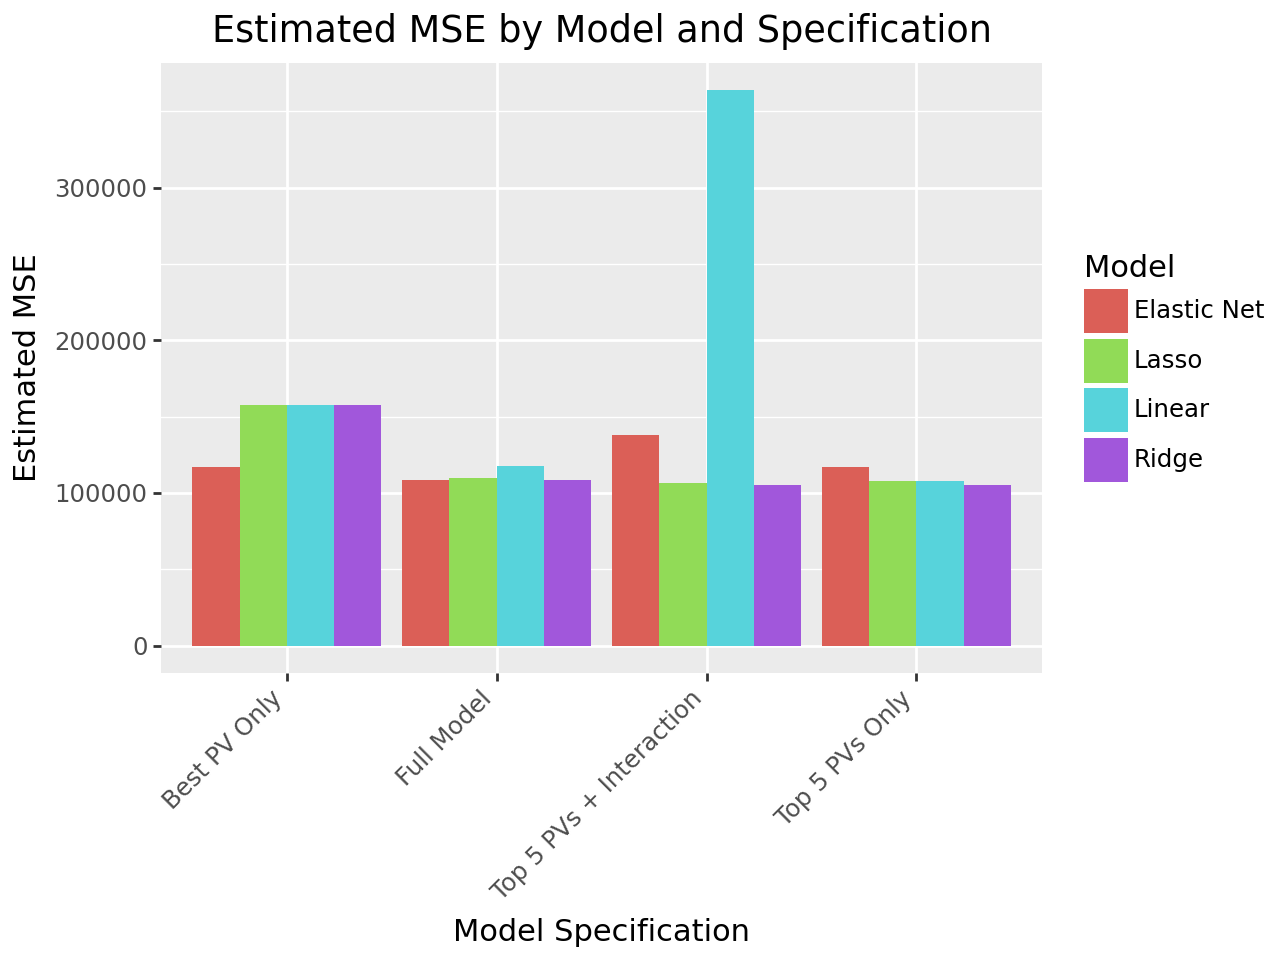

In [230]:
all_CV_melt = all_CV.reset_index().melt(id_vars='index', var_name='Model', value_name='Estimated MSE')
all_CV_melted = all_CV_melt.rename(columns={'index': 'Model Specification'})

plot_compare = (ggplot(all_CV_melted, aes(x='Model Specification', y='Estimated MSE', fill='Model')) +
    geom_bar(stat='identity', position='dodge') +
    labs(title='Estimated MSE by Model and Specification',
    x='Model Specification',
    y='Estimated MSE') +
    theme(axis_text_x=element_text(rotation=45, hjust=1))
)

plot_compare

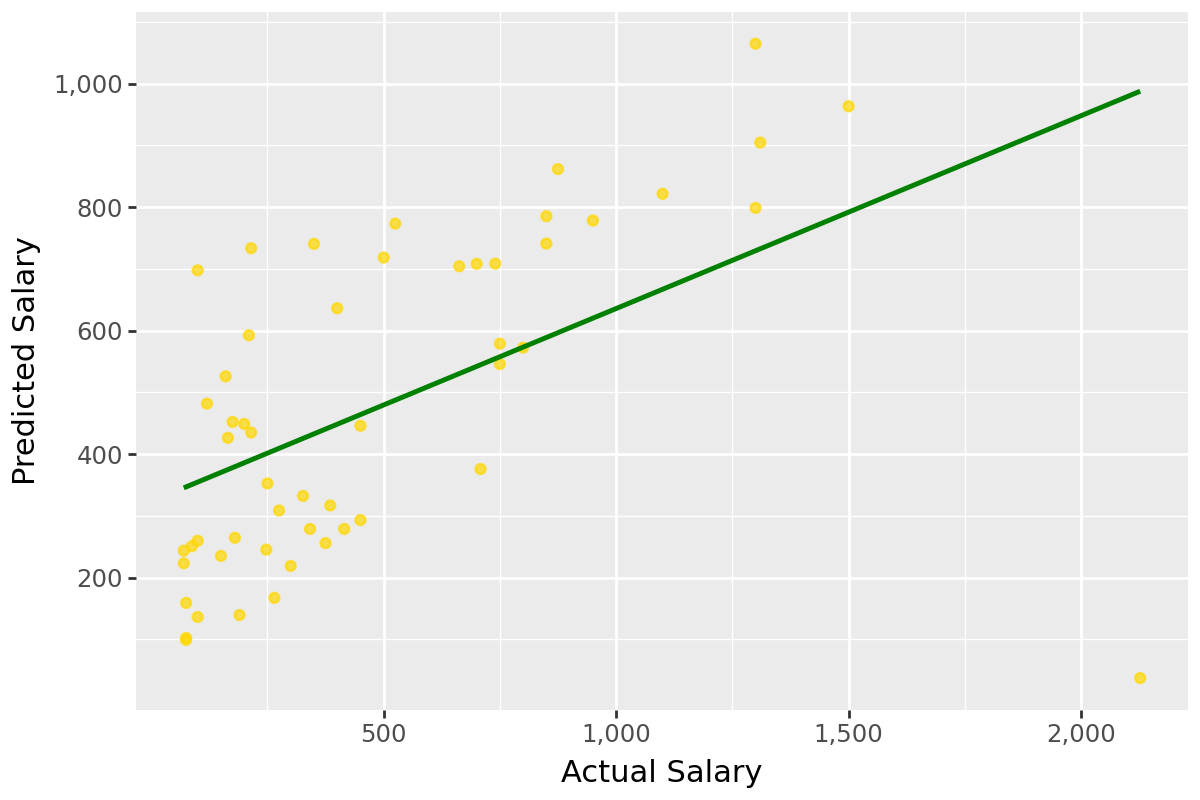

In [241]:
plot_best = pd.DataFrame({'Actual Salary': y_test_inter, 'Predicted Salary': y_pl3})

scatterplot_best = (
    ggplot(plot_best, aes(x='Actual Salary', y='Predicted Salary'))
    + geom_point(alpha=0.7, color='gold')
    + geom_smooth(method='lm', se=False, color='green')
    + scale_x_continuous(
        name='Actual Salary',
        breaks=[500, 1000, 1500, 2000, 2500],
        labels=['500', '1,000', '1,500', '2,000', '2,500']
      )
    + scale_y_continuous(
        name='Predicted Salary',
        breaks=[200, 400, 600, 800, 1000],
        labels=['200', '400', '600', '800', '1,000']
      )
    + theme(figure_size=(6, 4))
)

scatterplot_best